<a href="https://colab.research.google.com/github/shaikzayanahmed/ANVATHON/blob/main/DAV_LAB_06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.decomposition import PCA

In [ ]:
data= pd.DataFrame({
    "Study_Hours":[2,3,5,7,8,10],
    "attendence_percent":[50,60,65,75,85,95],
    "Assignment_Scores":[35,45,55,65,75,85],
    "Final_Marks":[30,40,50,68,82,94]
})
display(data)

,Study_Hours,attendence_percent,Assignment_Scores,Final_Marks
0,2,50,35,30
1,3,60,45,40
2,5,65,55,50
3,7,75,65,68
4,8,85,75,82
5,10,95,85,94


In [ ]:
features=data[["Study_Hours","attendence_percent","Assignment_Scores"]]

print("Minimum Values")
print(features.min())
print("Maximum Values")
print(features.max())
print("Mean Values")
print(features.mean)

Minimum Values
Study_Hours            2
attendence_percent    50
Assignment_Scores     35
dtype: int64
Maximum Values
Study_Hours           10
attendence_percent    95
Assignment_Scores     85
dtype: int64
Mean Values
<bound method DataFrame.mean of    Study_Hours  attendence_percent  Assignment_Scores
0            2                  50                 35
1            3                  60                 45
2            5                  65                 55
3            7                  75                 65
4            8                  85                 75
5           10                  95                 85>


(array([1, 2, 3]),
 [Text(1, 0, 'Study_Hours'),
  Text(2, 0, 'attendence_percent'),
  Text(3, 0, 'Assignment_Scores')])

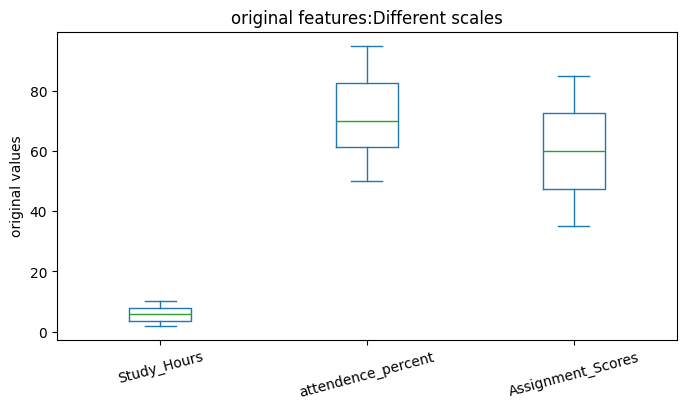

In [ ]:
features.plot(kind="box",figsize=(8,4))
plt.title("original features:Different scales")
plt.ylabel("original values")
plt.xticks(rotation=15)


In [ ]:
normalizer = MinMaxScaler()
normalized_array = normalizer.fit_transform(features)

normalized_df = pd.DataFrame(
    normalized_array,
    columns=features.columns,
    index=features.index
    )

display(normalized_df.round(3))

,Study_Hours,attendence_percent,Assignment_Scores
0,0.000,0.000,0.0
1,0.125,0.222,0.2
2,0.375,0.333,0.4
3,0.625,0.556,0.6
4,0.750,0.778,0.8
5,1.000,1.000,1.0


In [ ]:
print("minimum after normalization")
print(normalalized_df.min())
print("maximum after normalization")
print(normalalized_df.max())


minimum after normalization
Study_Hours           0.0
attendence_percent    0.0
Assignment_Scores     0.0
dtype: float64
maximum after normalization
Study_Hours           1.0
attendence_percent    1.0
Assignment_Scores     1.0
dtype: float64


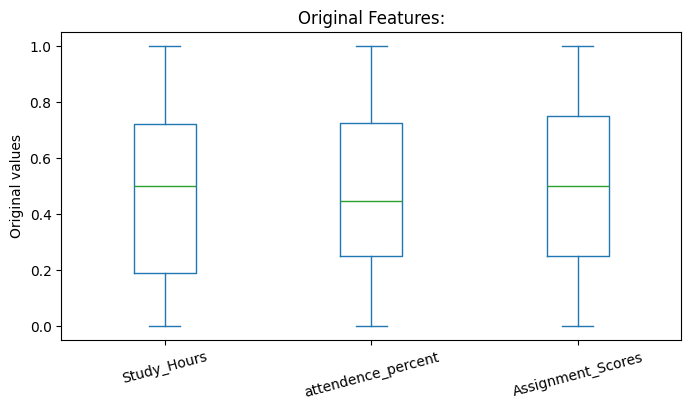

In [ ]:
normalized_df.plot(kind="box", figsize=(8,4))
plt.title("Original Features:")
plt.ylabel("Original values")
plt.xticks(rotation=15)
plt.show()

In [ ]:
Standardizer = StandardScaler()
standardized_array = Standardizer.fit_transform(features)

standardized_df = pd.DataFrame(
    standardized_array,
    columns=features.columns,
    index=features.index
    )

display(standardized_df.round(3))

,Study_Hours,attendence_percent,Assignment_Scores
0,-1.372,-1.427,-1.464
1,-1.014,-0.768,-0.878
2,-0.298,-0.439,-0.293
3,0.418,0.220,0.293
4,0.776,0.878,0.878
5,1.491,1.537,1.464


In [ ]:
print("mean after standardization")
print(standardized_df.min())
print("std after standardization")
print(standardized_df.std())

mean after standardization
Study_Hours          -1.372065
attendence_percent   -1.426935
Assignment_Scores    -1.463850
dtype: float64
std after standardization
Study_Hours           1.095445
attendence_percent    1.095445
Assignment_Scores     1.095445
dtype: float64


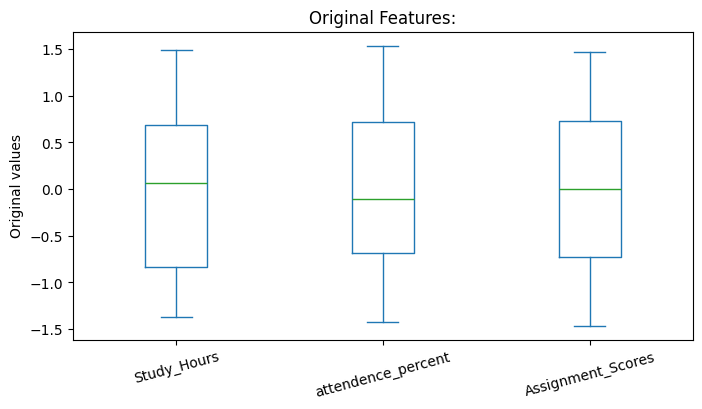

In [ ]:
standardized_df.plot(kind="box", figsize=(8,4))
plt.title("Original Features:")
plt.ylabel("Original values")
plt.xticks(rotation=15)
plt.show()

In [ ]:
scaled_features=StandardScaler().fit_transform(features)
pca=PCA(n_components=2)
pca_array=pca.fit_transform(scaled_features)

pca_df=pd.DataFrame(
    pca_array,
    columns=["PC1","PC2"],
    index=features.index
)

display(pca_df.round(3))

,PC1,PC2
0,-2.461,0.041
1,-1.536,-0.174
2,-0.595,0.097
3,0.537,0.141
4,1.462,-0.074
5,2.593,-0.030


In [ ]:
variance_ratios=pca.explained_variance_ratio_
for component,ratios in zip(("PCI","PCI"),variance_ratios):
  print(f"{component}:explains{ratios:.2%} of the variance")

total_retained=variance_ratios.sum()
print(f"total retained variance by two components:{total_retained:.2%}")

PCI:explains99.57% of the variance
PCI:explains0.38% of the variance
total retained variance by two components:99.94%


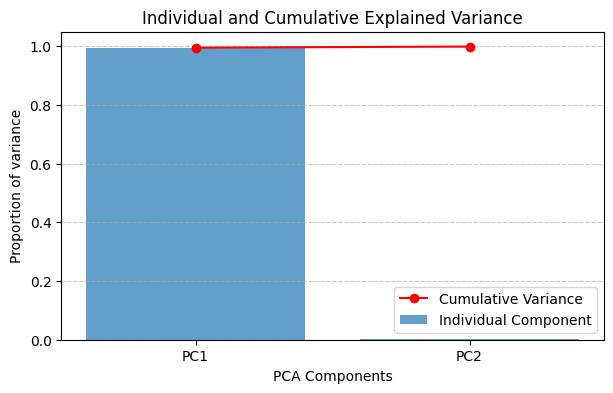

In [ ]:
omponent_names = ["PC1", "PC2"]
cumulative_variance = variance_ratio.cumsum()

plt.figure(figsize=(7, 4))
plt.bar(component_names, variance_ratio, label='Individual Component', alpha=0.7)
plt.plot(component_names, cumulative_variance, marker="o", color='red', label='Cumulative Variance')
plt.ylim(0, 1.05)
plt.ylabel("Proportion of variance")
plt.xlabel("PCA Components")
plt.title("Individual and Cumulative Explained Variance")
plt.legend()
plt.grid(True, axis='y', linestyle='--', alpha=0.7)
plt.show()